96
   6.1101   17.592
0  5.5277   9.1302
1  8.5186  13.6620
2  7.0032  11.8540
3  5.8598   6.8233
4  8.3829  11.8860


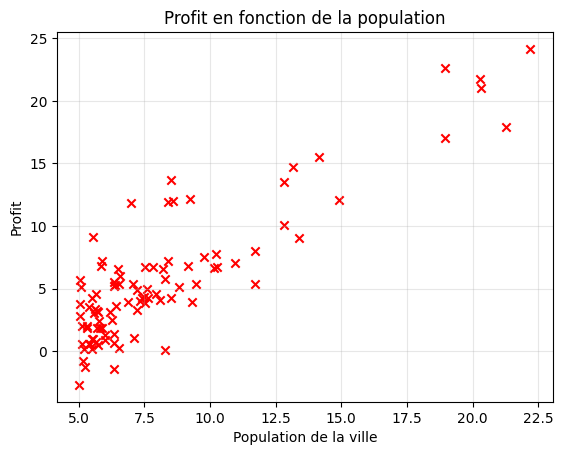

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("C:/Users/USER/PycharmProjects/TP2/Linear_regression/univariateLinearRegression.csv")
print(len(df))        # 97 villes
print(df.head())

X = df.iloc[0:len(df), 0]   # population (en 10 000 habitants)
Y = df.iloc[0:len(df), 1]   # profit (en 10 000 $)

plt.scatter(X, Y, marker='x', c='red')
plt.xlabel("Population de la ville")
plt.ylabel("Profit")
plt.title("Profit en fonction de la population")
plt.grid(alpha=.3)
plt.show()

Voici ce qu’on observe avec ce jeu de données de food trucks (à vérifier sur ton graphique) :

Relation globalement croissante. Plus la ville est peuplée, plus le profit tend à être élevé. La population est donc une variable explicative pertinente.
Tendance à peu près linéaire. Le nuage s’étire le long d’une droite, ce qui justifie le choix d’une régression linéaire simple.
Dispersion importante. Les points ne sont pas alignés. À population égale, les profits varient beaucoup, car d’autres facteurs jouent (concurrence, emplacement, revenus). Le modèle ne sera donc pas parfait.
Profits négatifs. Certaines petites villes ont un profit négatif, c’est-à-dire une perte. Ça suggère un seuil de population minimum pour être rentable.
Points atypiques. Quelques villes très peuplées ou très rentables sortent du nuage. Elles peuvent tirer la droite de régression vers le haut.
Concentration à gauche. La plupart des villes ont une petite population. Le modèle sera donc mieux estimé pour les petites et moyennes villes que pour les grandes, où les données sont rares.

Conclusion : une régression linéaire simple est adaptée. Elle donnera une tendance utile pour choisir la ville, mais avec une marge d’erreur notable.

Pente (slope)      : 1.2135472539083587
Ordonnée (intercept): -4.211504005424093
r                  : 0.8721572919685905
r² (variance expliquée): 0.7606583419339852
p-value            : 6.110460481642818e-31
Erreur std de la pente: 0.07021131328791101


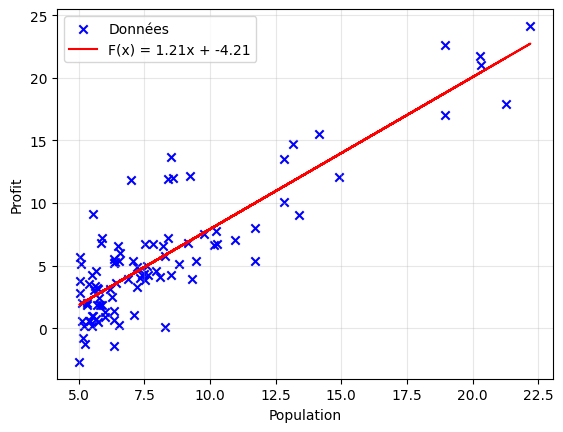

Profit prédit pour 20.27 : 20.38709883129834
MSE  : 6.91916380631601
RMSE : 2.630430346220179
R²   : 0.7606583419339846


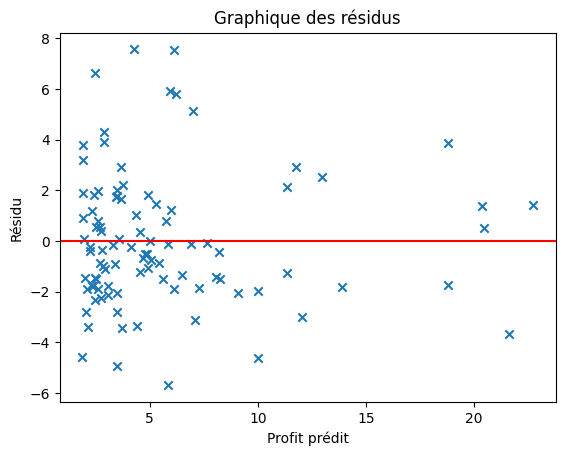

In [2]:
# --- Régression linéaire simple avec scipy ---
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)

print("Pente (slope)      :", slope)
print("Ordonnée (intercept):", intercept)
print("r                  :", r_value)
print("r² (variance expliquée):", r_value**2)
print("p-value            :", p_value)
print("Erreur std de la pente:", std_err)

# Fonction de prédiction F(x) = a*x + b
def F(x):
    return slope * x + intercept

# Prédictions sur les 97 villes
fitLine = F(X)

# Données + droite de régression
plt.scatter(X, Y, marker='x', c='blue', label='Données')
plt.plot(X, fitLine, c='r', label=f'F(x) = {slope:.2f}x + {intercept:.2f}')
plt.xlabel("Population")
plt.ylabel("Profit")
plt.legend()
plt.grid(alpha=.3)
plt.show()

# Prédiction du gain pour une population de 20.27
print("Profit prédit pour 20.27 :", F(20.27))

# --- Ajouts utiles pour évaluer le modèle ---
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("MSE  :", mean_squared_error(Y, fitLine))
print("RMSE :", np.sqrt(mean_squared_error(Y, fitLine)))
print("R²   :", r2_score(Y, fitLine))

# Résidus : écarts entre valeurs réelles et prédites
residus = Y - fitLine
plt.scatter(fitLine, residus, marker='x')
plt.axhline(0, c='r')
plt.xlabel("Profit prédit")
plt.ylabel("Résidu")
plt.title("Graphique des résidus")
plt.show()

Lecture des résultats
Valeur	Lecture
Pente = 1,21	Quand la population augmente d’une unité (+10 000 habitants), le profit prédit augmente de 1,21 unité (environ +12 100 $).
Ordonnée = −4,21	Pour une population de 0, le profit prédit est de −4,21 (environ −42 000 $). Ça n’a pas de sens concret : c’est juste le réglage de la droite. En revanche, la droite coupe zéro à x = 4,21 / 1,21 ≈ 3,5, soit environ 35 000 habitants. On peut en déduire un seuil de rentabilité.
r = 0,87	Forte corrélation positive entre population et profit.
R² = 0,76	La population explique environ 76 % de la variance du profit. Les 24 % restants viennent d’autres facteurs (concurrence, emplacement, revenus…).
p-value ≈ 6·10⁻³¹	Quasi nulle : la pente est significativement différente de 0. La relation n’est pas due au hasard.
Erreur std de la pente = 0,07	La pente est estimée précisément. Un intervalle de confiance à 95 % est d’environ 1,21 ± 2 × 0,07, soit [1,07 ; 1,35].
MSE = 6,92, RMSE = 2,63	Le modèle se trompe en moyenne d’environ 2,6 unités (environ 26 000 $).
F(20,27) = 20,39	Pour une ville d’environ 200 000 habitants, le profit prédit est d’environ 204 000 $.

1. Évaluer honnêtement. Tous les chiffres ci-dessus sont calculés sur les mêmes données que l’apprentissage. Ils sont donc optimistes. Fais un train_test_split ou une validation croisée pour avoir un R² et un RMSE de généralisation. Avec seulement 97 villes, la validation croisée est préférable.